# Does the score moderation survive covariate adjustment?

Continuous counterpart of Part 2 of `notebooks/2.28-paired-changes-and-covariates` and of the washout
analysis in `notebooks/2.32-medication-dose`. The question there was whether the tremor-dominant
colour x medication effect survived adjustment. Here it is whether `score:col:med`, the dependence of
the medication effect on tremor dominance (`2.25-score-moderated-mixed-model`), changes when
variables that travel with the score are allowed to moderate the medication effect themselves.

**Washout matters most.** `1.10-tremor-brady-score` found that more tremor-dominant patients had
shorter OFF-medication washouts (Spearman rho = -0.55, permutation p = 0.01), the same imbalance
`notebooks/2.32` found between the subtypes. A shorter washout means a less complete OFF state and
could by itself shrink an OFF-to-ON difference, so any score effect has to be read alongside it.

| Covariate | Varies | How it enters |
|---|---|---|
| OFF washout (hours) | between participants | standardised; interacted with every within-participant term, like the score |
| session order (OFF first) | between | +/- 0.5; same |
| site (Harvard vs Stanford) | between | +/- 0.5; same |
| severity (MDS-UPDRS part III, OFF exam) | between | standardised; same |
| colour-orientation mapping | **within** (differs between a patient's two sessions) | which colour carried the prior and which direction it favoured, each +/- 0.5, with their colour interactions, as in `notebooks/2.28` |

Unlike `notebooks/2.28`, severity is taken from the OFF exam rather than the patient's first listed
session, so it, like the score, cannot be moved by medication.

Every model keeps the reported random-effects structure, priors and sampler settings. Fits are cached
under `outputs/notebooks_2/mcmc_cache/`; expect 4 to 6 minutes per fit on the first run.

In [1]:
%matplotlib inline
%reload_ext autoreload
%autoreload 2
from imports import *

In [2]:
from config import dir_config
from src.utils.mcmc_cache import prepare_trials
from src.utils.motor_score import OUTPUT_DIR, SCORE, describe, fit_or_load, motor_scores, standardise

processed_dir = Path(dir_config.data.processed)
filtered_data = pd.read_csv(processed_dir / "processed_all_data_accu_60_filtered.csv", index_col=None)
metadata = pd.read_csv(processed_dir / "processed_metadata_all_data_accu_60.csv", encoding="latin1")
assert not str(OUTPUT_DIR).startswith(str(processed_dir.parents[0])), "never write to the data dir"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

scores = motor_scores(metadata)
trials = prepare_trials(filtered_data, scores.index)
assert scores[["off_meds_hrs", "off_med_first", "UPDRS_off", "site"]].notna().all().all(), "covariates must be complete"

## Covariates

In [3]:
between = {
    "washout": pd.Series(standardise(scores["off_meds_hrs"]), index=scores.index),
    "order": scores["off_med_first"] - 0.5,  # OFF first = +0.5
    "site": pd.Series(np.where(scores["site"] == "Harvard", 0.5, -0.5), index=scores.index),
    "severity": pd.Series(standardise(scores["UPDRS_off"]), index=scores.index),
}

session_condition = (metadata.dropna(subset=["treatment"]).assign(medication=lambda d: d["treatment"].str.lower())
                     .set_index(["subject_id", "medication"])["prior_condition"].astype(str))
condition = session_condition.reindex(pd.MultiIndex.from_arrays([trials["subject_id"], trials["medication"]])).to_numpy()
assert not pd.isna(condition).any()
red = np.where(np.char.startswith(condition.astype(str), "r"), 0.5, -0.5)
left = np.where(np.char.endswith(condition.astype(str), "l"), 0.5, -0.5)
mapping = {"red": red, "red:col": red * trials["col"].to_numpy(), "left": left, "left:col": left * trials["col"].to_numpy()}

pd.DataFrame(between).join(scores[[SCORE]]).corr(method="spearman").round(2)

,washout,order,site,severity,log2_trem_by_brady
washout,1.00,0.14,0.05,0.40,-0.54
order,0.14,1.00,0.15,-0.26,0.04
site,0.05,0.15,1.00,-0.17,0.06
severity,0.40,-0.26,-0.17,1.00,-0.25
log2_trem_by_brady,-0.54,0.04,0.06,-0.25,1.00


Spearman correlations among the between-participant moderators, for reference. A covariate strongly
correlated with the score makes the score's own coefficient less precise once both are in the model.

## Fits

In [4]:
MODELS = {
    "score only (2.25)": ([], False),
    "+ washout": (["washout"], False),
    "+ session order": (["order"], False),
    "+ site": (["site"], False),
    "+ severity (UPDRS OFF)": (["severity"], False),
    "+ colour-orientation mapping": ([], True),
    "+ all of the above": (["washout", "order", "site", "severity"], True),
}
CACHE_NAMES = {"score only (2.25)": "score_moderated", "+ washout": "adjusted_washout", "+ session order": "adjusted_order",
               "+ site": "adjusted_site", "+ severity (UPDRS OFF)": "adjusted_severity",
               "+ colour-orientation mapping": "adjusted_mapping", "+ all of the above": "adjusted_all"}

adjusted_rows, fits = [], {}
for label, (covariates, with_mapping) in MODELS.items():
    moderators = {"score": scores["score_z"], **{c: between[c] for c in covariates}}
    fits[label] = fitted = fit_or_load(CACHE_NAMES[label], trials, moderators, extra_columns=mapping if with_mapping else None)
    row = {"model": label, "extra terms": len(fitted.names) - 14}
    for term in ["score:col:med", "col:med"]:
        summary = describe(fitted.term(term))
        row |= {f"{term} {k}": v for k, v in summary.items() if k != "SD"}
    if "washout" in covariates:
        row["washout:col:med mean"] = fitted.term("washout:col:med").mean()
        row["washout:col:med P(> 0)"] = (fitted.term("washout:col:med") > 0).mean()
    diag = fitted.diagnostics()
    row |= {"divergences": fitted.divergences, "max r_hat": diag["r_hat"].max(), "min ESS": diag["ess_bulk"].min()}
    adjusted_rows.append(row)

adjusted = pd.DataFrame(adjusted_rows).set_index("model")
adjusted.round(3)

score_moderated: loaded cached draws (seed 0, fingerprint 7d2928d58ec6fecb)
adjusted_washout: loaded cached draws (seed 0, fingerprint e88a8bc1b334904c)
adjusted_order: loaded cached draws (seed 0, fingerprint 6176a26582979d79)
adjusted_site: loaded cached draws (seed 0, fingerprint 7a22e682e7a74c6e)
adjusted_severity: loaded cached draws (seed 0, fingerprint ea73bea3bff465af)
adjusted_mapping: loaded cached draws (seed 0, fingerprint 01d9f044c24224db)
adjusted_all: loaded cached draws (seed 0, fingerprint 46b3fce0603708e7)


,extra terms,score:col:med mean,score:col:med 2.5%,score:col:med 97.5%,score:col:med P(> 0),col:med mean,col:med 2.5%,col:med 97.5%,col:med P(> 0),divergences,max r_hat,min ESS,washout:col:med mean,washout:col:med P(> 0)
model,,,,,,,,,,,,,,
score only (2.25),0,0.112,-0.343,0.546,0.712,0.203,-0.202,0.627,0.834,0,1.009,395.207,NaN,NaN
+ washout,7,0.079,-0.352,0.522,0.646,0.205,-0.231,0.635,0.828,0,1.003,1610.062,-0.085,0.351
+ session order,7,0.114,-0.317,0.533,0.711,0.215,-0.213,0.652,0.841,0,1.003,1212.774,NaN,NaN
+ site,7,0.118,-0.332,0.569,0.695,0.202,-0.297,0.672,0.794,0,1.004,1434.096,NaN,NaN
+ severity (UPDRS OFF),7,0.144,-0.313,0.604,0.750,0.199,-0.238,0.641,0.822,0,1.004,1379.618,NaN,NaN
+ colour-orientation mapping,4,0.087,-0.337,0.518,0.667,0.144,-0.261,0.535,0.772,0,1.004,822.901,NaN,NaN
+ all of the above,32,0.001,-0.474,0.483,0.498,0.225,-0.226,0.680,0.847,0,1.004,1499.824,-0.443,0.054


### Figure

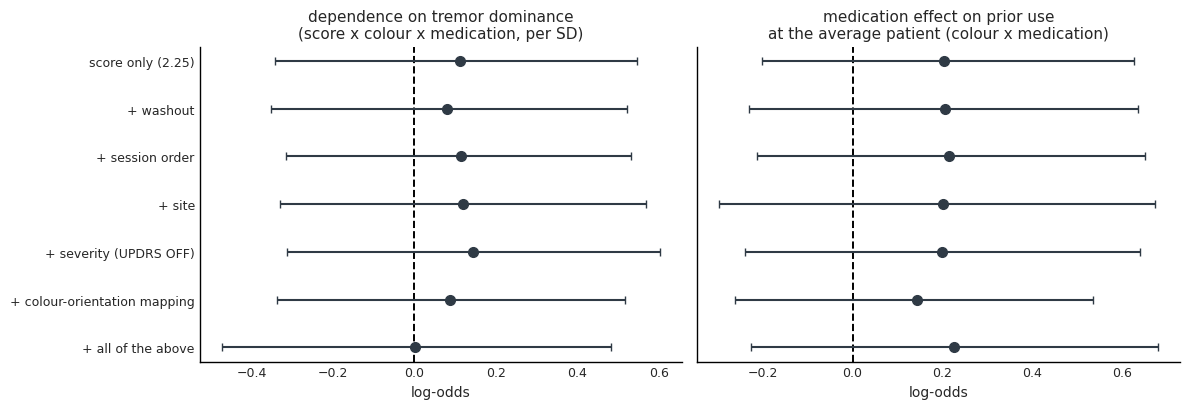

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
block = adjusted.iloc[::-1]
positions = np.arange(len(block))
for ax, term, title in [(axes[0], "score:col:med", "dependence on tremor dominance\n(score x colour x medication, per SD)"),
                        (axes[1], "col:med", "medication effect on prior use\nat the average patient (colour x medication)")]:
    ax.axvline(0, color="k", ls="--", lw=1.4)
    ax.errorbar(block[f"{term} mean"], positions, xerr=[block[f"{term} mean"] - block[f"{term} 2.5%"], block[f"{term} 97.5%"] - block[f"{term} mean"]],
                ls="", marker="o", ms=7, color="#2F3A45", capsize=3, lw=1.5)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("log-odds", fontsize=10)
    ax.tick_params(labelsize=9)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_yticks(positions)
axes[0].set_yticklabels(block.index, fontsize=9)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "covariate_adjusted_moderation.pdf", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "covariate_adjusted_moderation.png", dpi=200, bbox_inches="tight")
plt.show()

In [6]:
adjusted.to_csv(OUTPUT_DIR / "covariate_adjusted_moderation.csv")
print("wrote covariate_adjusted_moderation.csv and figure to", OUTPUT_DIR.relative_to(OUTPUT_DIR.parents[1]))

wrote covariate_adjusted_moderation.csv and figure to outputs/notebooks_2


## Results

Values are from this run. All fits: 0 divergences, max R-hat 1.004 or below (1.009 for the cached
score-only fit).

| Model | score x colour x medication | 95% interval | P(> 0) |
|---|---|---|---|
| score only (`2.25`) | +0.11 | -0.34 to +0.55 | 0.71 |
| + washout | +0.08 | -0.35 to +0.52 | 0.65 |
| + session order | +0.11 | -0.32 to +0.53 | 0.71 |
| + site | +0.12 | -0.33 to +0.57 | 0.70 |
| + severity (UPDRS OFF) | +0.14 | -0.31 to +0.60 | 0.75 |
| + colour-orientation mapping | +0.09 | -0.34 to +0.52 | 0.67 |
| + all of the above | +0.00 | -0.47 to +0.48 | 0.50 |

**No single covariate changes the conclusion.** The score slope stays between +0.08 and +0.14 with
each covariate added on its own, always with an interval spanning zero. The medication effect at the
average patient (`col:med`) stays between +0.14 and +0.23 throughout.

**Washout absorbs what little there is.** Adding washout alone moves the slope from +0.11 to +0.08.
With everything in the model the slope is zero, and washout's own interaction with colour x medication
is -0.44 per SD (P(> 0) = 0.05): patients with shorter washouts showed larger medication effects on
prior use. Washout correlates with the score (rho = -0.54) and with severity (+0.40), so these
coefficients are partly competing for the same variance. That model also adds 32 terms on 22
patients, so read it as a caution, not a finding: **the small tremor-dominance slope cannot be
separated from the fact that more tremor-dominant patients had shorter washouts.**

This differs from the categorical analysis (`notebooks/2.32`), where washout adjustment barely moved
the tremor-dominant `col:med` (+0.54 to +0.53). There the question was whether the effect *within*
tremor patients survived. Here it is whether the *dependence on* the score does, and washout is
confounded with exactly that dependence.

### Reporting

Report that the score x colour x medication slope is small and uncertain with or without adjustment.
If washout is discussed, note that it is correlated with tremor dominance in this sample, so the two
cannot be separated with 22 patients.